#Реккурентный поток с гамма-распределением

In [ ]:
import numpy as np
from scipy.stats import gamma
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf

N = 10000

# Параметры гамма-распределения
shape = 2.0   # параметр формы
scale = 1.0  # параметр масштаба

rng = np.random.default_rng(42)

# Генерируем интервалы между событиями
intervals = rng.gamma(shape, scale, N)

# Получаем моменты наступления событий
events = np.cumsum(intervals)

# Вывод всей трассы (первые 10 событий)
for i in range(10):
    print(
        f"Событие {i + 1}: "
        f"t = {events[i]:.4f}, "
        f"delta t = {intervals[i]:.4f}"
    )

Событие 1: t = 2.0918, delta t = 2.0918
Событие 2: t = 4.9272, delta t = 2.8353
Событие 3: t = 6.7644, delta t = 1.8372
Событие 4: t = 8.4094, delta t = 1.6451
Событие 5: t = 11.4887, delta t = 3.0793
Событие 6: t = 13.2421, delta t = 1.7534
Событие 7: t = 15.5881, delta t = 2.3460
Событие 8: t = 17.7776, delta t = 2.1895
Событие 9: t = 20.8550, delta t = 3.0774
Событие 10: t = 22.2942, delta t = 1.4392


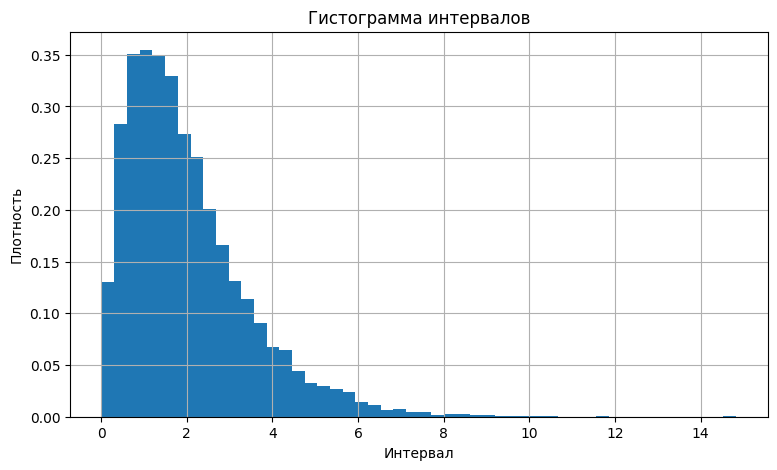

<Figure size 900x500 with 0 Axes>

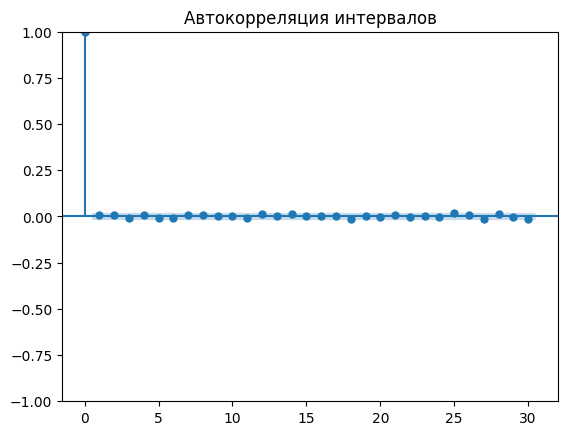


Результаты сравнения:
Gamma: AIC = 31704.14
Weibull: AIC = 31847.89
Lognormal: AIC = 32593.80
Exponential: AIC = 34011.09

Лучшее распределение: Gamma


In [ ]:
# intervals - массив интервалов между событиями

# 1. Гистограмма
plt.figure(figsize=(9, 5))

plt.hist(intervals, bins=50, density=True)

plt.title("Гистограмма интервалов")
plt.xlabel("Интервал")
plt.ylabel("Плотность")

plt.grid()
plt.show()


# 2. Автокорреляция
plt.figure(figsize=(9, 5))

plot_acf(intervals, lags=30)

plt.title("Автокорреляция интервалов")
plt.show()


# 3. Сравнение распределений через AIC

distributions = {
    "Gamma": stats.gamma,
    "Weibull": stats.weibull_min,
    "Exponential": stats.expon,
    "Lognormal": stats.lognorm
}

results = []

for name, distribution in distributions.items():

    params = distribution.fit(intervals, floc=0)

    log_likelihood = np.sum(
        distribution.logpdf(intervals, *params)
    )

    # Число оцениваемых параметров
    m = len(params) - 1

    aic = 2 * m - 2 * log_likelihood

    results.append((name, aic))


results.sort(key=lambda x: x[1])

print("\nРезультаты сравнения:")

for name, aic in results:
    print(f"{name}: AIC = {aic:.2f}")

print("\nЛучшее распределение:", results[0][0])

In [ ]:
import numpy as np
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox

# intervals — массив межсобытийных интервалов
intervals = np.asarray(intervals)

alpha = 0.05

# Проверка корректности данных
if len(intervals) < 30 or np.any(intervals <= 0):
    raise ValueError("Нужно не менее 30 положительных интервалов")


# 1. Проверка распределений

distributions = {
    "Гамма": stats.gamma,
    "Вейбулла": stats.weibull_min,
    "Экспоненциальное": stats.expon
}

print("ПРОВЕРКА РАСПРЕДЕЛЕНИЙ")

for name, distribution in distributions.items():

    # Оценка параметров распределения
    params = distribution.fit(intervals, floc=0)

    # Разбиваем данные на интервалы по квантилям
    probabilities = np.linspace(0, 1, 11)
    edges = distribution.ppf(probabilities, *params)

    observed, _ = np.histogram(intervals, bins=edges)

    # Для каждого интервала ожидаем одинаковое число наблюдений
    expected = np.full(len(observed), len(intervals) / len(observed))

    # Критерий хи-квадрат
    chi2, p_value = stats.chisquare(observed, expected)

    print(f"\n{name}")
    print("Статистика χ²:", chi2)
    print("p-value:", p_value)

    if p_value <= alpha:
        print("H0 отвергается")
    else:
        print("H0 принимается")



ПРОВЕРКА РАСПРЕДЕЛЕНИЙ

Гамма
Статистика χ²: 3.93
p-value: 0.9159589977267666
H0 принимается

Вейбулла
Статистика χ²: 64.084
p-value: 2.1737734687088249e-10
H0 отвергается

Экспоненциальное
Статистика χ²: 1741.368
p-value: 0.0
H0 отвергается

ПРОВЕРКА АВТОКОРРЕЛЯЦИИ
Статистика Ljung-Box: 5.659991021657941
p-value: 0.8429748009070401
H0 не отвергается: значимая автокорреляция не обнаружена


# Реккурентный поток с Вейбулл распределнием

In [ ]:
from scipy.stats import weibull_min

N = 10000

# Параметры распределения Вейбулла
shape = 2.0   # параметр формы
scale = 1.0  # параметр масштаба

rng = np.random.default_rng(0)
intervalsW = rng.weibull(shape, size=N)
eventsW = np.cumsum(intervals)

# Вывод всей трассы (первые 10 событий)
for i in range(10):
    print(
        f"Событие {i + 1}: "
        f"t = {eventsW[i]:.4f}, "
        f"delta t = {intervalsW[i]:.4f}"
    )

Событие 1: t = 2.0918, delta t = 0.8246
Событие 2: t = 4.9272, delta t = 1.0098
Событие 3: t = 6.7644, delta t = 0.1407
Событие 4: t = 8.4094, delta t = 0.0476
Событие 5: t = 11.4887, delta t = 0.7419
Событие 6: t = 13.2421, delta t = 1.2767
Событие 7: t = 15.5881, delta t = 0.8207
Событие 8: t = 17.7776, delta t = 0.8691
Событие 9: t = 20.8550, delta t = 1.6783
Событие 10: t = 22.2942, delta t = 2.4613


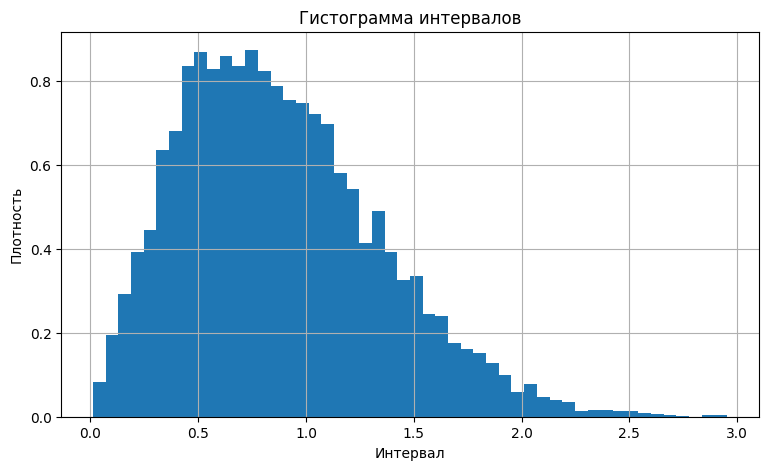

<Figure size 900x500 with 0 Axes>

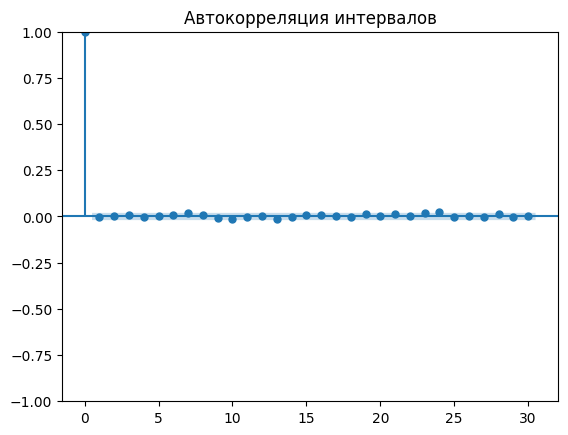


Результаты сравнения:
Weibull: AIC = 11808.94
Gamma: AIC = 12084.94
Lognormal: AIC = 13520.15
Exponential: AIC = 17513.12

Лучшее распределение: Weibull


In [ ]:

# intervals - массив интервалов между событиями

# 1. Гистограмма
plt.figure(figsize=(9, 5))

plt.hist(intervalsW, bins=50, density=True)

plt.title("Гистограмма интервалов")
plt.xlabel("Интервал")
plt.ylabel("Плотность")

plt.grid()
plt.show()


# 2. Автокорреляция
plt.figure(figsize=(9, 5))

plot_acf(intervalsW, lags=30)

plt.title("Автокорреляция интервалов")
plt.show()


# 3. Сравнение распределений через AIC

distributions = {
    "Gamma": stats.gamma,
    "Weibull": stats.weibull_min,
    "Exponential": stats.expon,
    "Lognormal": stats.lognorm
}

results = []

for name, distribution in distributions.items():

    params = distribution.fit(intervalsW, floc=0)

    log_likelihood = np.sum(
        distribution.logpdf(intervalsW, *params)
    )

    # Число оцениваемых параметров
    m = len(params) - 1

    aic = 2 * m - 2 * log_likelihood

    results.append((name, aic))


results.sort(key=lambda x: x[1])

print("\nРезультаты сравнения:")

for name, aic in results:
    print(f"{name}: AIC = {aic:.2f}")

print("\nЛучшее распределение:", results[0][0])

In [ ]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# intervals — массив межсобытийных интервалов
intervals = np.asarray(intervalsW)

alpha = 0.05

# Проверка корректности данных
if len(intervals) < 30 or np.any(intervals <= 0):
    raise ValueError("Нужно не менее 30 положительных интервалов")


# 1. Проверка распределений

distributions = {
    "Гамма": stats.gamma,
    "Вейбулла": stats.weibull_min,
    "Экспоненциальное": stats.expon
}

print("ПРОВЕРКА РАСПРЕДЕЛЕНИЙ")

for name, distribution in distributions.items():

    # Оценка параметров распределения
    params = distribution.fit(intervals, floc=0)

    # Разбиваем данные на интервалы по квантилям
    probabilities = np.linspace(0, 1, 11)
    edges = distribution.ppf(probabilities, *params)

    observed, _ = np.histogram(intervals, bins=edges)

    # Для каждого интервала ожидаем одинаковое число наблюдений
    expected = np.full(len(observed), len(intervals) / len(observed))

    # Критерий хи-квадрат
    chi2, p_value = stats.chisquare(observed, expected)

    print(f"\n{name}")
    print("Статистика χ²:", chi2)
    print("p-value:", p_value)

    if p_value <= alpha:
        print("H0 отвергается")
    else:
        print("H0 принимается")


ПРОВЕРКА РАСПРЕДЕЛЕНИЙ

Гамма
Статистика χ²: 86.946
p-value: 6.661785566858975e-15
H0 отвергается

Вейбулла
Статистика χ²: 12.384
p-value: 0.1925164906726528
H0 принимается

Экспоненциальное
Статистика χ²: 4552.3279999999995
p-value: 0.0
H0 отвергается

ПРОВЕРКА АВТОКОРРЕЛЯЦИИ
Статистика Ljung-Box: 7.7592735375955515
p-value: 0.6523375122247663
H0 не отвергается: значимая автокорреляция не обнаружена


#ММРР поток с 2 состояниями

In [ ]:
import numpy as np
import pandas as pd

def generate_mmpp_2(N, lambda1=2.0, lambda2=8.0, q12=0.5, q21=0.3, seed=42):
    rng = np.random.default_rng(seed)

    lambdas = [lambda1, lambda2]          # интенсивности событий в состояниях 0 и 1
    # матрица интенсивностей переходов
    Q = np.array([
        [-q12, q12],
        [q21, -q21]
    ])

    state = 0                             # начальное состояние
    current_time = 0.0

    event_times = []
    states_at_event = []

    while len(event_times) < N:
        # Интенсивность событий в текущем состоянии
        lam = lambdas[state] #Выбор интенсивности по текущему состоянию

        # Интенсивность выхода из текущего состояния
        exit_rate = -Q[state, state]

        # Для текущего состояния генерируются два экспоненциальных времени: время до события всегда рассчитывается с той интенсивностью, которая актуальна именно в текущем состоянии
        t_event = rng.exponential(scale=1/lam) if lam > 0 else np.inf   #до следующего события потока
        t_transition = rng.exponential(scale=1/exit_rate) if exit_rate > 0 else np.inf #до перехода в другое состояние

        # Выбираем, что произойдёт раньше
        if t_event < t_transition:
            # Сначала происходит событие (приход заявки)
            current_time += t_event
            event_times.append(current_time)
            states_at_event.append(state + 1)  # сохраняем состояние (1 или 2)
        else:
            # Сначала происходит переход в другое состояние
            current_time += t_transition  #Когда время перехода оказывается меньше времени до события, происходит смена состояния
            # Вероятности перехода в другие состояния
            probs = Q[state].copy()
            probs[state] = 0
            probs /= exit_rate  # нормировка
            state = rng.choice(2, p=probs)

    # Вычисляем интервалы между событиями
    intervals = [event_times[0]]  # первый интервал от 0 до первого события
    for i in range(1, len(event_times)):
        intervals.append(event_times[i] - event_times[i-1])

    trace = pd.DataFrame({
        "event_id": np.arange(1, N + 1),
        "event_time": event_times,
        "interval": intervals,
        "state": states_at_event
    })

    return trace

# Пример запуска
N = 10000
trace = generate_mmpp_2(N)

print("Первые 10 событий:")
print(trace.head(10))

#print("\nПоследние 10 событий:")
#print(trace.tail(10))


Первые 10 событий:
   event_id  event_time  interval  state
0         1    1.202104  1.202104      1
1         2    1.943275  0.741171      2
2         3    2.242808  0.299532      1
3         4    3.035819  0.793011      2
4         5    3.075216  0.039397      2
5         6    3.126839  0.051623      2
6         7    3.154787  0.027947      2
7         8    3.308172  0.153386      2
8         9    3.360308  0.052136      2
9        10    3.369943  0.009635      2


Стационарное распределение: [0.375 0.625]
Средняя интенсивность: 5.75
Распределение состояний при поступлении событий: [0.13043478 0.86956522]

Количество интервалов: 9999


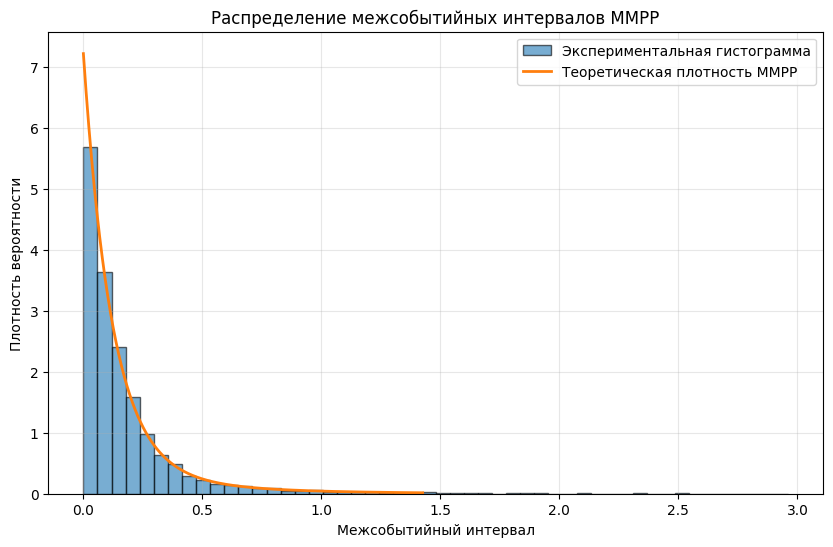


========== КРИТЕРИЙ ХИ-КВАДРАТ ==========
Число групп: 15
Статистика chi2: 10.392439243924391
Число степеней свободы: 14
p-value: 0.7329658265757422
H0 не отвергается.
Распределение интервалов согласуется с теоретическим MMPP.


<Figure size 1000x500 with 0 Axes>

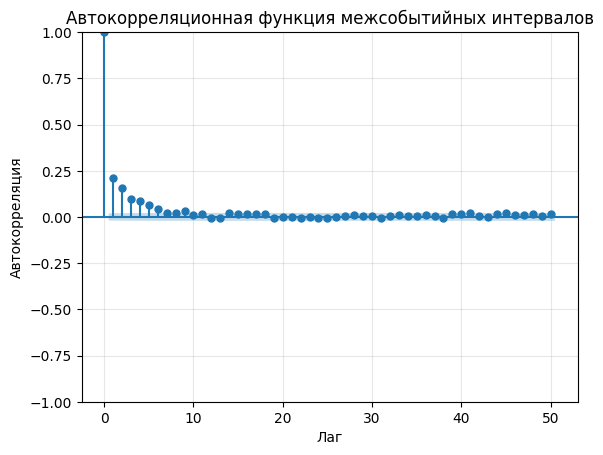


========== ТЕСТ ЛЬЮНГА-БОКСА ==========
       lb_stat      lb_pvalue
5   890.329332  3.296471e-190
10  929.737474  2.528877e-193
20  949.728146  2.026779e-188
30  954.011668  2.575318e-181
50  981.840612  4.067231e-173


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import expm
from scipy.optimize import brentq
from scipy.stats import chisquare
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox


# 1. Параметры MMPP


lambda1 = 2.0
lambda2 = 8.0
q12 = 0.5
q21 = 0.3

lambdas = np.array([lambda1, lambda2])

Q = np.array([
    [-q12, q12],
    [q21, -q21]
])

Lambda = np.diag(lambdas)

# Стационарное распределение марковской цепи
pi = np.array([
    q21 / (q12 + q21),
    q12 / (q12 + q21)
])

mean_lambda = np.sum(pi * lambdas)

# Распределение состояний в моменты поступления событий
alpha = pi * lambdas / mean_lambda

print("Стационарное распределение:", pi)
print("Средняя интенсивность:", mean_lambda)
print("Распределение состояний при поступлении событий:", alpha)



# 2. Теоретическая функция распределения


A = Q - Lambda
ones = np.ones(2) #вектор единиц

def theoretical_cdf(t):  #экспериментальная плотность распределения
    if t <= 0:       #вероятность того, что событие уже произошло, меньше или равна нулю
        return 0.0

    survival = alpha @ expm(A * t) @ ones  #@ - матричное умножениe, expm() вычисляет матричную экспоненту, т.о. вычисляем вероятность того, что за время \(t\) не произойдёт ни одного события

    return 1 - survival #получаем вероятность того, что следующий интервал будет меньше или равен \(t\).


def theoretical_pdf(t):  #теоретическая плотность
    if t < 0:
        return 0.0

    return alpha @ expm(A * t) @ lambdas    #вычисляется плотность распределения



# 3. Подготовка экспериментальных данных


# Исключаем первый интервал, поскольку начальное состояние
# генератора фиксировано и не является стационарным.

intervals = trace["interval"].values[1:] #экспериментальные интервалы

N = len(intervals)

print("\nКоличество интервалов:", N)



# 4. Гистограмма и теоретическая плотность


x = np.linspace(0, np.percentile(intervals, 99.5), 500)

plt.figure(figsize=(10, 6))

plt.hist(
    intervals,
    bins=50,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="Экспериментальная гистограмма"
)

plt.plot(
    x,
    [theoretical_pdf(t) for t in x],
    linewidth=2,
    label="Теоретическая плотность MMPP"
)

plt.xlabel("Межсобытийный интервал")
plt.ylabel("Плотность вероятности")
plt.title("Распределение межсобытийных интервалов MMPP")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# 5. Критерий согласия Пирсона


# Число групп
k = 15

# Границы групп с равными теоретическими вероятностями
bounds = []

for j in range(1, k):

    probability = j / k

    upper = 1.0

    while theoretical_cdf(upper) < probability:
        upper *= 2

    boundary = brentq(
        lambda t: theoretical_cdf(t) - probability,
        0,
        upper
    )

    bounds.append(boundary)

bins = np.array([0] + bounds + [np.inf])

# Наблюдаемые частоты
observed, _ = np.histogram(intervals, bins=bins)

# Теоретические частоты
expected = np.full(k, N / k)

# Статистика Пирсона
chi2_stat, p_value = chisquare(
    observed,
    expected
)

df = k - 1

print("\n========== КРИТЕРИЙ ХИ-КВАДРАТ ==========")
print("Число групп:", k)
print("Статистика chi2:", chi2_stat)
print("Число степеней свободы:", df)
print("p-value:", p_value)

alpha_test = 0.05

if p_value > alpha_test:
    print("H0 не отвергается.")
    print("Распределение интервалов согласуется с теоретическим MMPP.")
else:
    print("H0 отвергается.")
    print("Распределение интервалов не согласуется с теоретическим MMPP.")



# ММРР поток с 3 состояниями

In [ ]:
import numpy as np
import pandas as pd

def generate_mmpp_3(N, q12, q23, q31, lambda1, lambda2, lambda3, seed=42):
    rng = np.random.default_rng(seed)

    # Интенсивности событий в состояниях 0, 1, 2
    lambdas = [lambda1, lambda2, lambda3]

    # Матрица интенсивностей переходов Q (3x3)
    Q = np.array([
        [-q12, q12, 0],
        [ 0, -q23, q23],
        [q31, 0, -q31]
    ])

    state = 0                 # начальное состояние (0-индексация)
    current_time = 0.0

    event_times = []
    states_at_event = []      # состояние в момент события (для вывода сделаем 1,2,3)

    while len(event_times) < N:
        lam = lambdas[state]
        exit_rate = -Q[state, state]  # суммарная интенсивность выхода из состояния

        # время до события всегда рассчитывается с той интенсивностью, которая актуальна именно в текущем состоянии
        t_event = rng.exponential(scale=1/lam) if lam > 0 else np.inf
        t_transition = rng.exponential(scale=1/exit_rate) if exit_rate > 0 else np.inf

        if t_event < t_transition:
            # Сначала происходит событие потока
            current_time += t_event
            event_times.append(current_time)
            states_at_event.append(state + 1)  # сохраняем как 1,2,3 для удобства
        else:
            # Сначала происходит переход в другое состояние
            current_time += t_transition

            # Вероятности перехода в другие состояния (нормированные)
            probs = Q[state].copy()
            probs[state] = 0
            if exit_rate > 0:
                probs /= exit_rate
            state = rng.choice(3, p=probs)

    # Вычисляем интервалы между событиями
    intervals = [event_times[0]]  # интервал от 0 до первого события
    for i in range(1, len(event_times)):
        intervals.append(event_times[i] - event_times[i-1])

    trace = pd.DataFrame({
        "event_id": np.arange(1, N + 1),
        "event_time": event_times,
        "interval": intervals,
        "state": states_at_event
    })

    return trace

# Параметры модели
N = 10000
q12 = 0.5   # интенсивность перехода 1→2
q23 = 0.3   # интенсивность перехода 2→3
q31 = 0.4   # интенсивность перехода 3→1
lambda1 = 2.0
lambda2 = 8.0
lambda3 = 4.0

# Генерация 10 000 событий
trace = generate_mmpp_3(N, q12, q23, q31, lambda1, lambda2, lambda3, seed=42)

print("Первые 10 событий:")
print(trace.head(10))

#print("\nПоследние 10 событий:")
#print(trace.tail(10))


Первые 10 событий:
   event_id  event_time  interval  state
0         1    1.202104  1.202104      1
1         2    1.943275  0.741171      2
2         3    2.225199  0.281923      3
3         4    2.658030  0.432832      3
4         5    2.965927  0.307896      3
5         6    2.988821  0.022894      3
6         7    3.214121  0.225300      3
7         8    3.525967  0.311846      3
8         9    3.985460  0.459493      3
9        10    4.149409  0.163949      3



Количество интервалов: 9999


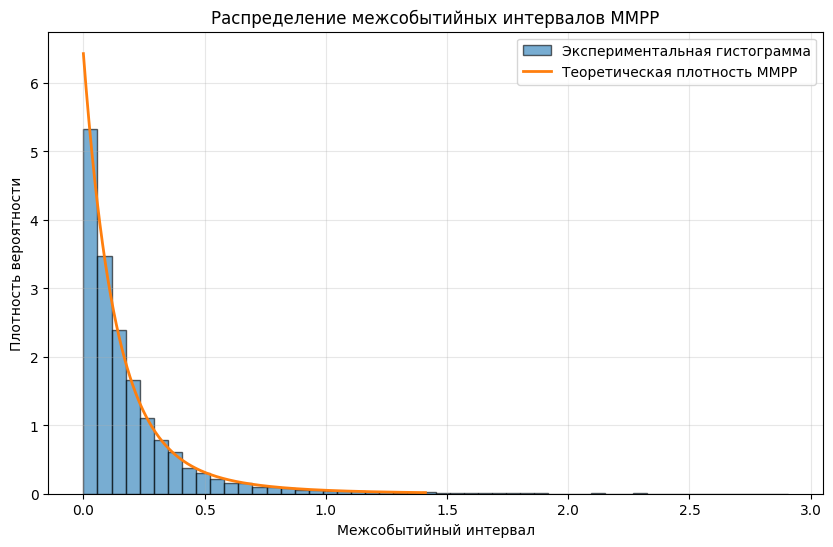


========== КРИТЕРИЙ ХИ-КВАДРАТ ==========
Число групп: 15
Статистика chi2: 25.402940294029406
Число степеней свободы: 14
p-value: 0.030791693021281426
H0 отвергается.
Распределение интервалов не согласуется с теоретическим MMPP.


<Figure size 1000x500 with 0 Axes>

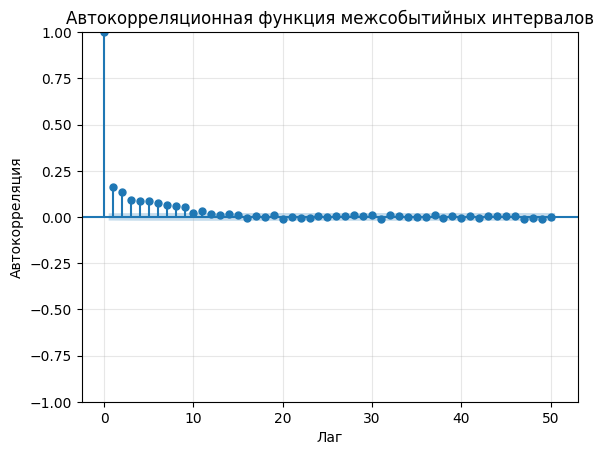


========== ТЕСТ ЛЬЮНГА-БОКСА ==========
       lb_stat      lb_pvalue
5   684.646189  1.025389e-145
10  853.044151  8.080781e-177
20  873.064125  4.226128e-172
30  877.561039  3.199964e-165
50  886.150656  2.097550e-153


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import expm
from scipy.optimize import brentq
from scipy.stats import chisquare
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox



# 1. Параметры MMPP


lambdas = np.array([2.0, 8.0, 4.0])

Q = np.array([
    [-0.5, 0.5, 0],
    [0, -0.3, 0.3],
    [0.4, 0, -0.4]
])

Lambda = np.diag(lambdas)

# Стационарное распределение
A = np.vstack([Q.T, np.ones(3)])
b = np.array([0.0, 0.0, 0.0, 1.0])

pi = np.linalg.lstsq(A, b, rcond=None)[0]

# Распределение состояний в моменты событий
mean_lambda = pi @ lambdas
alpha = pi * lambdas / mean_lambda

# Матрица для теоретического распределения
A_m = Q - Lambda

ones = np.ones(3)

def theoretical_cdf(t):
    if t <= 0:
        return 0.0

    return 1 - alpha @ expm(A_m * t) @ ones

def theoretical_pdf(t):
    if t < 0:
        return 0.0

    return alpha @ expm(A_m * t) @ lambdas



# 3. Подготовка экспериментальных данных


# Исключаем первый интервал, поскольку начальное состояние
# генератора фиксировано и не является стационарным.

intervals = trace["interval"].values[1:]

N = len(intervals)

print("\nКоличество интервалов:", N)



# 4. Гистограмма и теоретическая плотность


x = np.linspace(0, np.percentile(intervals, 99.5), 500)

plt.figure(figsize=(10, 6))

plt.hist(
    intervals,
    bins=50,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="Экспериментальная гистограмма"
)

plt.plot(
    x,
    [theoretical_pdf(t) for t in x],
    linewidth=2,
    label="Теоретическая плотность MMPP"
)

plt.xlabel("Межсобытийный интервал")
plt.ylabel("Плотность вероятности")
plt.title("Распределение межсобытийных интервалов MMPP")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



# 5. Критерий согласия Пирсона


# Число групп
k = 15

# Границы групп с равными теоретическими вероятностями
bounds = []

for j in range(1, k):

    probability = j / k

    upper = 1.0

    while theoretical_cdf(upper) < probability:
        upper *= 2

    boundary = brentq(
        lambda t: theoretical_cdf(t) - probability,
        0,
        upper
    )

    bounds.append(boundary)

bins = np.array([0] + bounds + [np.inf])

# Наблюдаемые частоты
observed, _ = np.histogram(intervals, bins=bins)

# Теоретические частоты
expected = np.full(k, N / k)

# Статистика Пирсона
chi2_stat, p_value = chisquare(
    observed,
    expected
)

df = k - 1

print("\n========== КРИТЕРИЙ ХИ-КВАДРАТ ==========")
print("Число групп:", k)
print("Статистика chi2:", chi2_stat)
print("Число степеней свободы:", df)
print("p-value:", p_value)

alpha_test = 0.05

if p_value > alpha_test:
    print("H0 не отвергается.")
    print("Распределение интервалов согласуется с теоретическим MMPP.")
else:
    print("H0 отвергается.")
    print("Распределение интервалов не согласуется с теоретическим MMPP.")




In [ ]:
# 1. ПАРАМЕТРЫ MMPP С ТРЕМЯ СОСТОЯНИЯМИ


N = 10000

lambdas = np.array([2.0, 8.0, 4.0])

Q = np.array([
    [-0.5,  0.5,  0.0],
    [ 0.0, -0.3,  0.3],
    [ 0.4,  0.0, -0.4]
])

Lambda = np.diag(lambdas)

n_states = 3
ones = np.ones(3)


# 2. ТЕОРЕТИЧЕСКИЕ ХАРАКТЕРИСТИКИ

# Стационарное распределение марковской цепи

M = np.vstack([Q.T, np.ones(3)])
b = np.array([0.0, 0.0, 0.0, 1.0])

pi = np.linalg.lstsq(M, b, rcond=None)[0]

# Средняя интенсивность

mean_lambda = pi @ lambdas

# Распределение состояний в моменты событий

alpha = pi * lambdas / mean_lambda

# Матрица для вычисления распределения интервалов

A = Q - Lambda

print("Стационарное распределение:", pi)
print("Распределение состояний при событиях:", alpha)
print("Средняя интенсивность:", mean_lambda)


# 3. ГЕНЕРАЦИЯ MMPP-3

def generate_mmpp_3(N, seed=42):

    rng = np.random.default_rng(seed)

    state = 0
    current_time = 0.0

    event_times = []
    states_at_event = []

    while len(event_times) < N:

        lam = lambdas[state]
        exit_rate = -Q[state, state]

        # Время до события

        t_event = rng.exponential(1 / lam)

        # Время до перехода

        t_transition = rng.exponential(1 / exit_rate)

        if t_event < t_transition:

            current_time += t_event

            event_times.append(current_time)
            states_at_event.append(state + 1)

        else:

            current_time += t_transition

            probs = Q[state].copy()
            probs[state] = 0
            probs /= exit_rate

            state = rng.choice(3, p=probs)

    intervals = np.diff(np.concatenate(([0.0], event_times)))

    trace = pd.DataFrame({
        "event_id": np.arange(1, N + 1),
        "event_time": event_times,
        "interval": intervals,
        "state": states_at_event
    })

    return trace


# Генерация с периодом разогрева

burn_in = 5000

trace_full = generate_mmpp_3(N + burn_in)

trace = trace_full.iloc[burn_in:].copy().reset_index(drop=True)

intervals = trace["interval"].values[1:]

N = len(intervals)

print("\nКоличество интервалов:", N)


# 4. ТЕОРЕТИЧЕСКАЯ ФУНКЦИЯ РАСПРЕДЕЛЕНИЯ


def theoretical_cdf(t):

    if t <= 0:
        return 0.0

    survival = alpha @ expm(A * t) @ ones

    return 1 - survival


def theoretical_pdf(t):

    if t < 0:
        return 0.0

    return alpha @ expm(A * t) @ lambdas


# 5. ГИСТОГРАММА И ТЕОРЕТИЧЕСКАЯ ПЛОТНОСТЬ


x = np.linspace(
    0,
    np.percentile(intervals, 99.5),
    500
)

plt.figure(figsize=(10, 6))

plt.hist(
    intervals,
    bins=50,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="Экспериментальная гистограмма"
)

plt.plot(
    x,
    [theoretical_pdf(t) for t in x],
    linewidth=2,
    label="Теоретическая плотность MMPP-3"
)

plt.xlabel("Межсобытийный интервал")
plt.ylabel("Плотность вероятности")
plt.title("Распределение межсобытийных интервалов MMPP-3")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# 6. КРИТЕРИЙ СОГЛАСИЯ ХИ-КВАДРАТ

k = 15

bounds = []

for j in range(1, k):

    probability = j / k

    upper = 1.0

    while theoretical_cdf(upper) < probability:
        upper *= 2

    boundary = brentq(
        lambda t: theoretical_cdf(t) - probability,
        0,
        upper
    )

    bounds.append(boundary)

bins = np.array([0] + bounds + [np.inf])

observed, _ = np.histogram(intervals, bins=bins)

expected = np.full(k, N / k)

chi2_stat, p_value = chisquare(
    observed,
    expected
)

print("\n========== КРИТЕРИЙ ХИ-КВАДРАТ ==========")

print("Наблюдаемые частоты:", observed)
print("Ожидаемые частоты:", expected)
print("Статистика chi2:", chi2_stat)
print("Степени свободы:", k - 1)
print("p-value:", p_value)

if p_value > 0.05:
    print("H0 не отвергается")
else:
    print("H0 отвергается")


# МАР поток с 2 состояними

In [ ]:
import numpy as np
import pandas as pd

def generate_map_2(N, a, b, lambda1, lambda2, seed=42):
    rng = np.random.default_rng(seed)

    # D0: переходы БЕЗ события
    D0 = np.array([
        [-(a + lambda1), a],
        [b, -(b + lambda2)]
    ], dtype=float)

    # D1: переходы С событием (интенсивности событий в состояниях)
    D1 = np.array([
        [lambda1, 0],
        [0, lambda2]
    ], dtype=float)

    state = 0
    current_time = 0.0

    event_times = []
    states_at_event = []

    while len(event_times) < N:
        rate = -D0[state, state]  # общая интенсивность ухода из состояния

        # Время до следующего акта (событие или смена состояния)
        wait_time = rng.exponential(scale=1.0 / rate)
        current_time += wait_time

        # Вероятность, что это событие (а не смена состояния)
        event_prob = D1[state, state] / rate

        if rng.random() < event_prob:
            # Приход заявки
            event_times.append(current_time)
            states_at_event.append(state + 1)
        else:
            # Смена состояния без события
            row = D0[state].copy()
            row[state] = 0.0  # запрещаем «переход в себя»

            # Суммарная интенсивность переходов в другие состояния
            sum_trans = row.sum()

            if sum_trans <= 0:
                # Если из состояния некуда переходить (не должно быть при корректных параметрах),
                # остаёмся в том же состоянии
                continue

            probs = row / sum_trans  # нормируем так, чтобы точно сумма была 1
            # Явно подправим возможную ошибку округления, чтобы сумма была ровно 1
            probs = probs / probs.sum()

            state = rng.choice(2, p=probs)

    # Интервалы между событиями
    intervals = [event_times[0]]
    for i in range(1, len(event_times)):
        intervals.append(event_times[i] - event_times[i-1])

    trace = pd.DataFrame({
        "event_id": np.arange(1, N + 1),
        "event_time": event_times,
        "interval": intervals,
        "state": states_at_event
    })

    return trace

# Параметры
N = 10000
a = 0.5
b = 0.3
lambda1 = 2.0
lambda2 = 8.0

trace = generate_map_2(N, a, b, lambda1, lambda2, seed=42)

print("Первые 10 событий:")
print(trace.head(10))
print("\nПоследние 10 событий:")
print(trace.tail(10))
print("\nКоличество событий:", len(trace))


Первые 10 событий:
   event_id  event_time  interval  state
0         1    0.961683  0.961683      1
1         2    1.915588  0.953904      1
2         3    2.326584  0.410996      2
3         4    2.452676  0.126092      2
4         5    2.583883  0.131208      2
5         6    2.630497  0.046614      2
6         7    2.649024  0.018527      2
7         8    2.686997  0.037973      2
8         9    2.736755  0.049757      2
9        10    3.026010  0.289255      1

Последние 10 событий:
      event_id   event_time  interval  state
9990      9991  1762.662145  0.081190      2
9991      9992  1762.683873  0.021729      2
9992      9993  1762.772754  0.088881      2
9993      9994  1762.787902  0.015148      2
9994      9995  1762.910825  0.122923      2
9995      9996  1763.002367  0.091543      2
9996      9997  1763.430651  0.428284      2
9997      9998  1763.432914  0.002263      2
9998      9999  1763.640875  0.207961      2
9999     10000  1763.727619  0.086744      2

Количество 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.linalg import expm
from scipy.stats import chisquare
from scipy.optimize import brentq

# Параметры MAP
D0 = np.array([
    [-(a + lambda1), a],
    [b, -(b + lambda2)]
])

D1 = np.diag([lambda1, lambda2])

# Стационарное распределение скрытой цепи
pi = np.array([b / (a + b), a / (a + b)])

# Средняя интенсивность
mean_lambda = pi @ np.array([lambda1, lambda2])

# Распределение состояний в моменты событий
alpha = pi * np.array([lambda1, lambda2]) / mean_lambda

ones = np.ones(2)

# Теоретическая функция распределения интервалов
def theoretical_cdf(t):
    return 1 - alpha @ expm(D0 * t) @ ones

# Теоретическая плотность
def theoretical_pdf(t):
    return alpha @ expm(D0 * t) @ D1 @ ones


intervals = trace["interval"].values

# Гистограмма
t_grid = np.linspace(0, np.quantile(intervals, 0.995), 500)

pdf = np.array([
    theoretical_pdf(t) for t in t_grid
])

plt.figure(figsize=(9, 5))

plt.hist(
    intervals,
    bins=30,
    density=True,
    alpha=0.6,
    edgecolor="black",
    label="Эмпирическая гистограмма"
)

plt.plot(
    t_grid,
    pdf,
    "r",
    linewidth=2,
    label="Теоретическая плотность MAP"
)

plt.xlabel("Межсобытийный интервал")
plt.ylabel("Плотность")
plt.title("Проверка MAP: гистограмма и теоретическая PDF")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Число интервалов
k = 10
N = len(intervals)

# Находим границы интертервалов по теоретическим квантилям
quantiles = []

for j in range(1, k):
    p = j / k

    upper = 1.0
    while theoretical_cdf(upper) < p:
        upper *= 2

    q = brentq(
        lambda t: theoretical_cdf(t) - p,
        0,
        upper
    )

    quantiles.append(q)

bins = np.array([0] + quantiles + [np.inf])

# Эмпирические частоты
observed, _ = np.histogram(intervals, bins=bins)

# Теоретические частоты
expected = np.full(k, N / k)

# Статистика Пирсона
chi2_stat = np.sum(
    (observed - expected)**2 / expected
)

# Обычный p-value (ориентировочный для MAP из-за зависимости интервалов)
chi2_result = chisquare(observed, expected)

print("Эмпирические частоты:", observed)
print("Теоретические частоты:", expected)

print("\nХи-квадрат статистика:", chi2_stat)
print("Обычный p-value:", chi2_result.pvalue)

if chi2_result.pvalue >= 0.05:
    print("Нет оснований отвергать H0.")
else:
    print("H0 отвергается.")